# HC-MAE sanity check

Sinha & Lucheroni (Applied Energy 2025) propose **Heterogeneous Curves MAE** for comparing two bid curves: step-interpolate both onto a 10 000-point common volume grid, take mean |ΔP|. Implemented in [`metrics/hc_mae.py`](../src/aemo_curves/metrics/hc_mae.py).

This notebook checks the metric makes visual sense — closest pairs should *look* close, most-different pairs should look different, and the ordering between them should track a human eye.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from aemo_curves.embeddings import load_embedding_table
from aemo_curves.metrics import curve_hc_mae_distance

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

train = load_embedding_table('train', 'demand')
rng = np.random.default_rng(123)
sample = train.iloc[rng.choice(len(train), size=200, replace=False)].reset_index(drop=True)
anchor = sample.iloc[0]
print(f'anchor: {anchor["Trading Date"]}  interval {anchor["Interval Number"]}  '
      f'{len(anchor["curve_qty"])} steps  P∈[{min(anchor["curve_price"]):.0f},{max(anchor["curve_price"]):.0f}]')

dists = np.array([
    curve_hc_mae_distance(anchor['curve_qty'], anchor['curve_price'],
                          r['curve_qty'], r['curve_price'])
    for _, r in sample.iloc[1:].iterrows()
])
order = np.argsort(dists)
print(f'HC-MAE range over {len(dists)} pairs: [{dists.min():.1f}, {dists.max():.1f}]  median={np.median(dists):.1f}')

anchor: 2022-07-02  interval 7  24 steps  P∈[-1000,200]
HC-MAE range over 199 pairs: [14.7, 546.6]  median=183.8


## Closest vs most different (3 each)

Reference anchor (red dashed) overlaid with the 3 closest neighbours (top row) and the 3 most-different (bottom row).

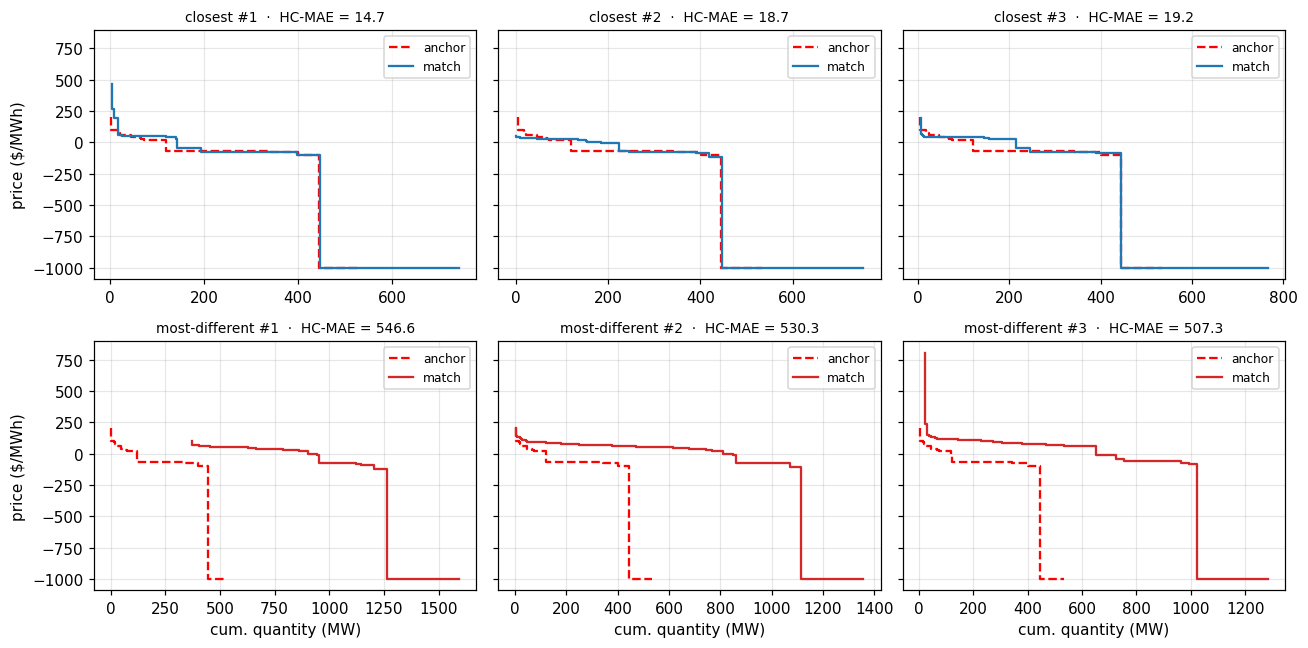

In [2]:
def step_plot(ax, qty, price, **kw):
    ax.step(qty, price, where='pre', **kw)

fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharey=True)
for col, idx in enumerate(order[:3]):
    ax = axes[0, col]
    other = sample.iloc[idx + 1]
    step_plot(ax, anchor['curve_qty'], anchor['curve_price'], color='red', lw=1.5, ls='--', label='anchor')
    step_plot(ax, other['curve_qty'], other['curve_price'], color='C0', lw=1.5, label='match')
    ax.set_title(f'closest #{col+1}  ·  HC-MAE = {dists[idx]:.1f}', fontsize=9)
    ax.legend(fontsize=8, loc='best')
for col, idx in enumerate(order[-3:][::-1]):
    ax = axes[1, col]
    other = sample.iloc[idx + 1]
    step_plot(ax, anchor['curve_qty'], anchor['curve_price'], color='red', lw=1.5, ls='--', label='anchor')
    step_plot(ax, other['curve_qty'], other['curve_price'], color='C3', lw=1.5, label='match')
    ax.set_title(f'most-different #{col+1}  ·  HC-MAE = {dists[idx]:.1f}', fontsize=9)
    ax.legend(fontsize=8, loc='best')
for ax in axes[-1, :]:
    ax.set_xlabel('cum. quantity (MW)')
axes[0, 0].set_ylabel('price ($/MWh)')
axes[1, 0].set_ylabel('price ($/MWh)')
plt.tight_layout(); plt.show()

## Ranked grid: different → similar

12 evenly-spaced quantiles of HC-MAE shown left-to-right, top-to-bottom. The ordering should look like a smooth visual transition from "nothing in common" to "essentially identical". If it doesn't, the metric isn't doing what we expect.

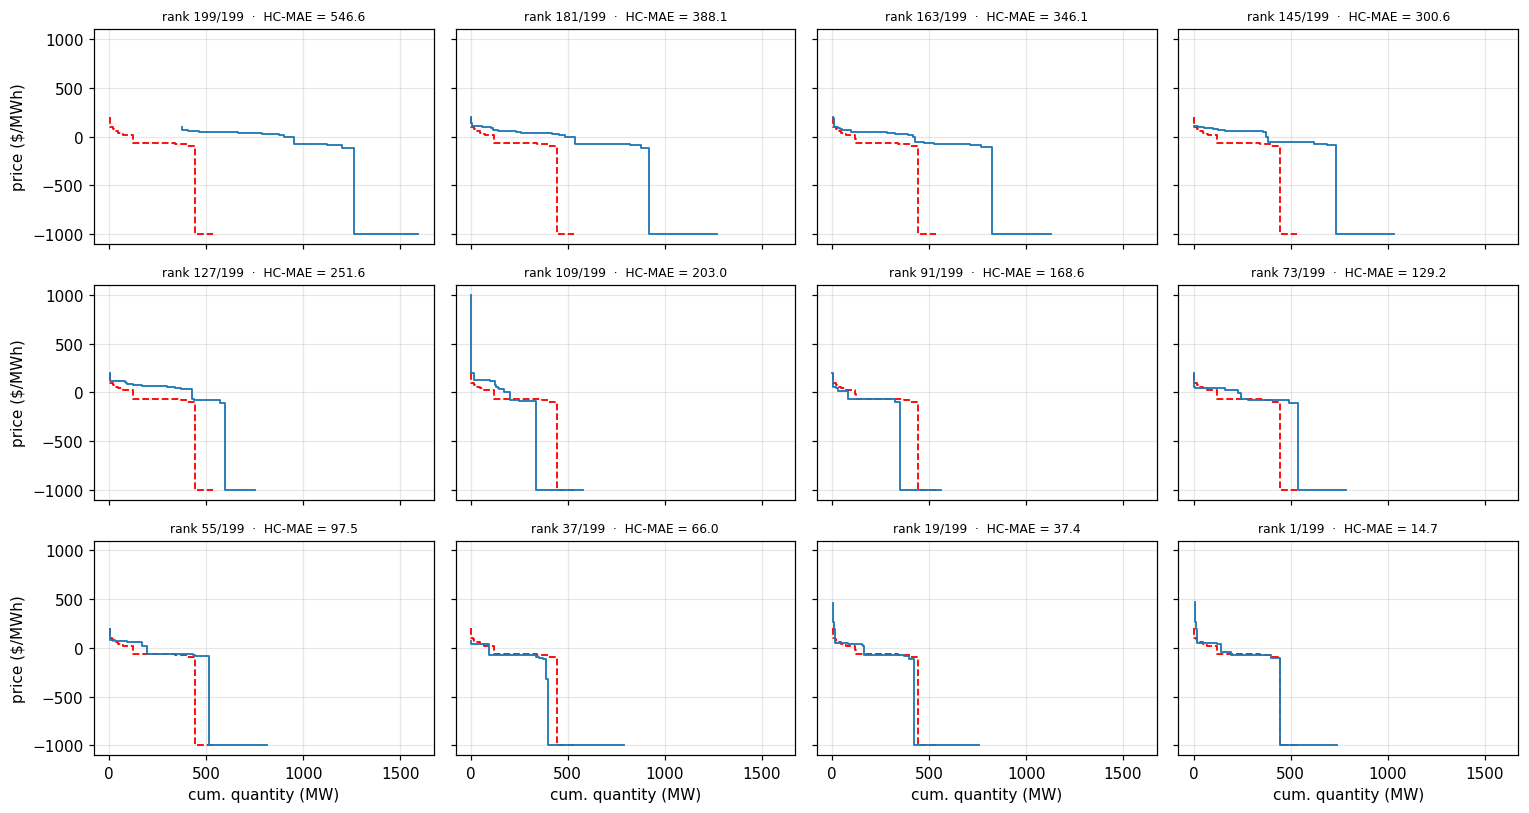

In [3]:
n_show = 12
# pick quantile positions from largest HC-MAE down to smallest
pick = np.linspace(len(order) - 1, 0, n_show).astype(int)
fig, axes = plt.subplots(3, 4, figsize=(14, 7.5), sharex=True, sharey=True)
for ax, rank in zip(axes.flat, pick):
    idx = order[rank]
    other = sample.iloc[idx + 1]
    step_plot(ax, anchor['curve_qty'], anchor['curve_price'], color='red', lw=1.2, ls='--')
    step_plot(ax, other['curve_qty'], other['curve_price'], color='C0', lw=1.2)
    ax.set_title(f'rank {rank+1}/{len(order)}  ·  HC-MAE = {dists[idx]:.1f}', fontsize=8)
for ax in axes[-1, :]:
    ax.set_xlabel('cum. quantity (MW)')
for ax in axes[:, 0]:
    ax.set_ylabel('price ($/MWh)')
plt.tight_layout(); plt.show()

## HC-MAE distribution and per-quantile table

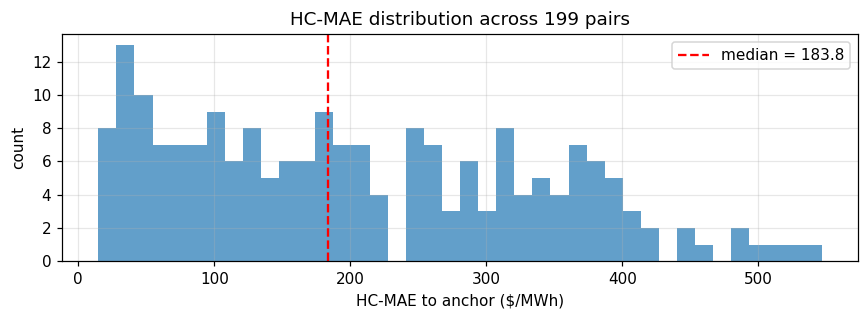

quantile  HC-MAE  pair_date  pair_interval  n_steps_other
     p00   14.68 2021-08-03             10             32
     p05   31.14 2024-01-20             15             43
     p25   93.92 2022-12-04             48             22
     p50  183.83 2023-11-16             42             23
     p75  310.99 2022-09-23             31             29
     p95  418.73 2023-07-18             20             47
    p100  546.63 2021-12-08             24             51


In [4]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(dists, bins=40, color='C0', alpha=0.7)
ax.axvline(np.median(dists), color='red', ls='--', label=f'median = {np.median(dists):.1f}')
ax.set_xlabel('HC-MAE to anchor ($/MWh)'); ax.set_ylabel('count')
ax.set_title(f'HC-MAE distribution across {len(dists)} pairs')
ax.legend(); plt.tight_layout(); plt.show()

qs = [0.0, 0.05, 0.25, 0.5, 0.75, 0.95, 1.0]
rows = []
for q in qs:
    idx = order[int(round(q * (len(order) - 1)))]
    other = sample.iloc[idx + 1]
    rows.append({
        'quantile': f'p{int(q*100):02d}',
        'HC-MAE': round(dists[idx], 2),
        'pair_date': str(other['Trading Date']),
        'pair_interval': int(other['Interval Number']),
        'n_steps_other': len(other['curve_qty']),
    })
print(pd.DataFrame(rows).to_string(index=False))

## Head-to-head with Wasserstein

Same 199 pairs scored under W₁ too. Scatter, correlation, and overlaid histograms.

W₁ range: [29.5, 454.6]  median=176.4
HC-MAE range: [14.7, 546.6]  median=183.8
Spearman(W₁, HC-MAE) = -0.3859   Pearson = -0.3240


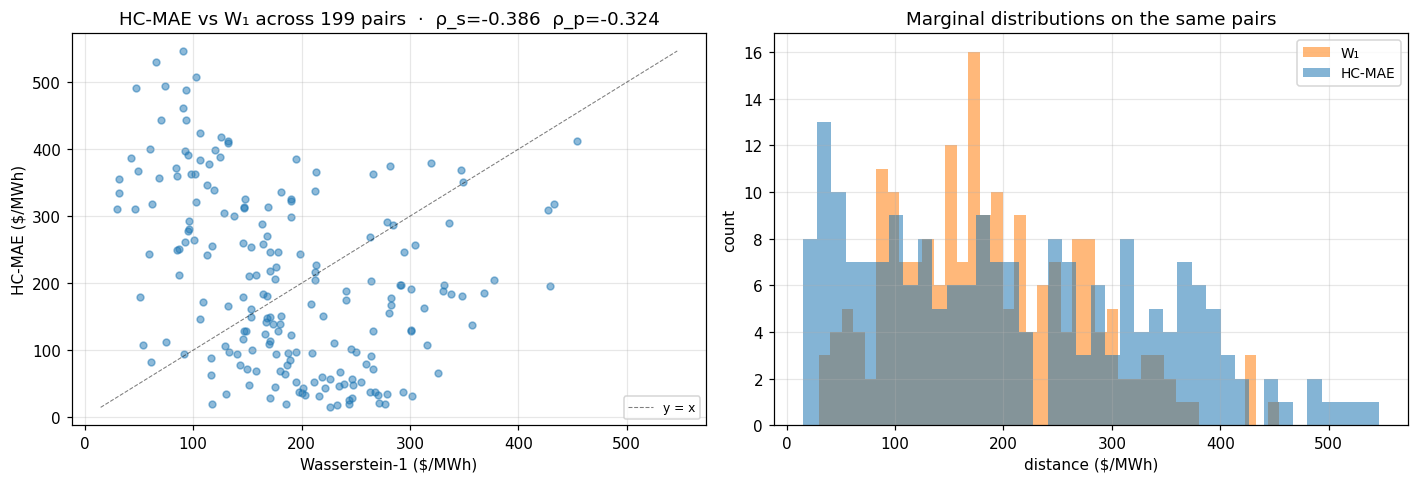

In [5]:
from aemo_curves.metrics import curve_wasserstein_distance
from scipy.stats import spearmanr, pearsonr

W = np.array([
    curve_wasserstein_distance(anchor['curve_qty'], anchor['curve_price'],
                               r['curve_qty'], r['curve_price'])
    for _, r in sample.iloc[1:].iterrows()
])
rho_s = float(spearmanr(W, dists).statistic)
rho_p = float(pearsonr(W, dists).statistic)
print(f'W₁ range: [{W.min():.1f}, {W.max():.1f}]  median={np.median(W):.1f}')
print(f'HC-MAE range: [{dists.min():.1f}, {dists.max():.1f}]  median={np.median(dists):.1f}')
print(f'Spearman(W₁, HC-MAE) = {rho_s:.4f}   Pearson = {rho_p:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(W, dists, s=20, alpha=0.5, color='C0')
axes[0].set_xlabel('Wasserstein-1 ($/MWh)'); axes[0].set_ylabel('HC-MAE ($/MWh)')
axes[0].set_title(f'HC-MAE vs W₁ across {len(W)} pairs  ·  ρ_s={rho_s:.3f}  ρ_p={rho_p:.3f}')
# diagonal reference line in normalised units to show "perfect agreement"
lo, hi = min(W.min(), dists.min()), max(W.max(), dists.max())
axes[0].plot([lo, hi], [lo, hi], 'k--', lw=0.7, alpha=0.5, label='y = x')
axes[0].legend(loc='lower right', fontsize=8)

axes[1].hist(W, bins=40, alpha=0.55, color='C1', label='W₁')
axes[1].hist(dists, bins=40, alpha=0.55, color='C0', label='HC-MAE')
axes[1].set_xlabel('distance ($/MWh)'); axes[1].set_ylabel('count')
axes[1].set_title('Marginal distributions on the same pairs')
axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

## Where the two metrics disagree

For each pair, z-score both metrics, take `Δz = z(W₁) − z(HC-MAE)`.

- **Top row** below: `Δz` most positive → **W₁ relatively high, HC-MAE relatively low**. Wasserstein says these are different; HC-MAE says they're similar. Look at the plots — which metric matches your eye?
- **Bottom row**: `Δz` most negative → **W₁ relatively low, HC-MAE relatively high**. The reverse case.

Each panel shows both metrics' actual values and their z-scores so you can judge.

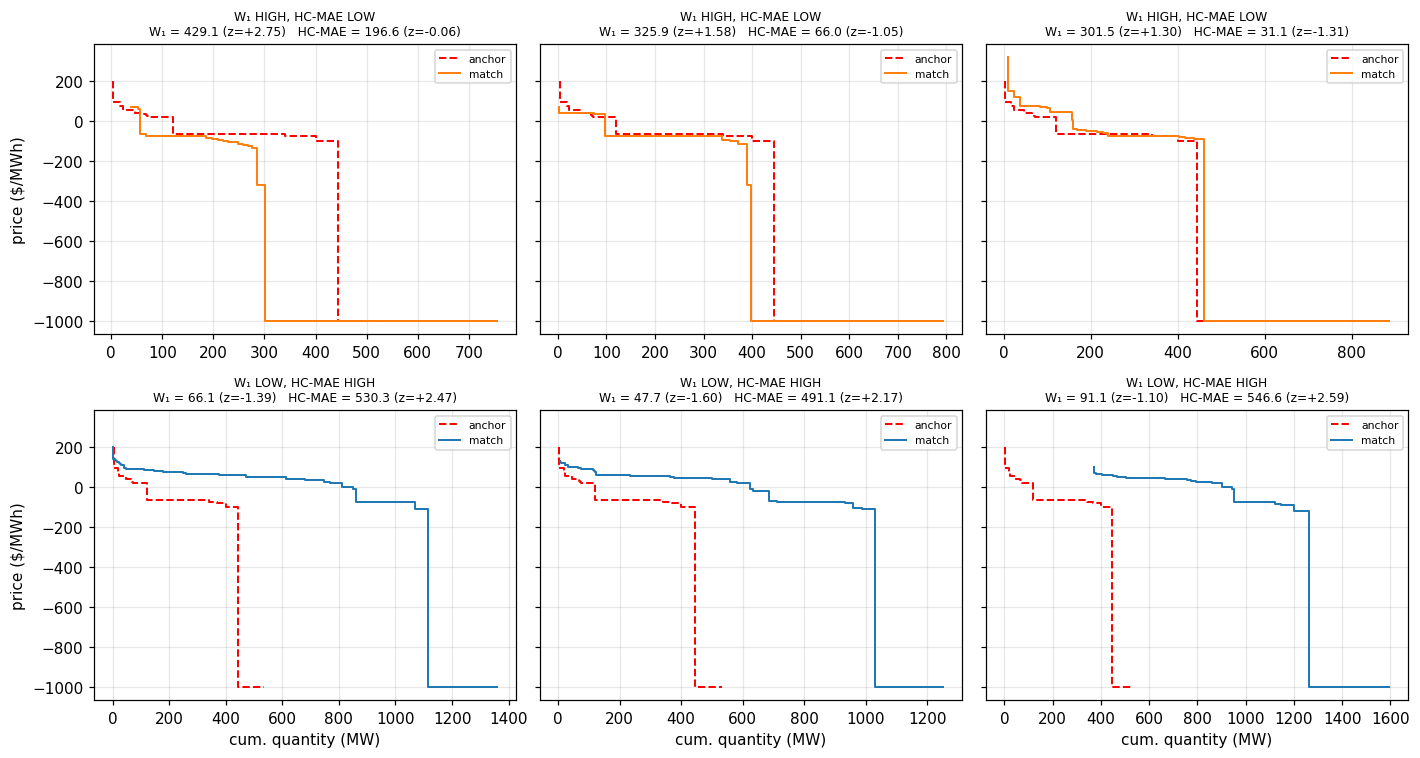

       case  pair_date  interval     W1  HC_MAE  z_W1  z_HC  delta_z
W₁ ≫ HC-MAE 2024-02-14         4 429.07  196.59  2.75 -0.06     2.81
W₁ ≫ HC-MAE 2024-02-22        41 325.90   65.95  1.58 -1.05     2.62
W₁ ≫ HC-MAE 2024-01-20        15 301.51   31.14  1.30 -1.31     2.61
HC-MAE ≫ W₁ 2022-07-26        23  66.11  530.29 -1.39  2.47    -3.85
HC-MAE ≫ W₁ 2022-08-19        24  47.66  491.14 -1.60  2.17    -3.77
HC-MAE ≫ W₁ 2021-12-08        24  91.08  546.63 -1.10  2.59    -3.69


In [6]:
z_W = (W - W.mean()) / W.std()
z_HC = (dists - dists.mean()) / dists.std()
dz = z_W - z_HC                                 # positive → W relatively higher

idx_w_high = np.argsort(-dz)[:3]                # W₁ much higher than HC-MAE
idx_hc_high = np.argsort(dz)[:3]                # HC-MAE much higher than W₁

fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey=True)
for col, idx in enumerate(idx_w_high):
    ax = axes[0, col]
    other = sample.iloc[idx + 1]
    step_plot(ax, anchor['curve_qty'], anchor['curve_price'], color='red', lw=1.3, ls='--', label='anchor')
    step_plot(ax, other['curve_qty'], other['curve_price'], color='C1', lw=1.3, label='match')
    ax.set_title(f'W₁ HIGH, HC-MAE LOW\n'
                 f'W₁ = {W[idx]:.1f} (z={z_W[idx]:+.2f})   HC-MAE = {dists[idx]:.1f} (z={z_HC[idx]:+.2f})',
                 fontsize=8)
    ax.legend(fontsize=7, loc='best')
for col, idx in enumerate(idx_hc_high):
    ax = axes[1, col]
    other = sample.iloc[idx + 1]
    step_plot(ax, anchor['curve_qty'], anchor['curve_price'], color='red', lw=1.3, ls='--', label='anchor')
    step_plot(ax, other['curve_qty'], other['curve_price'], color='C0', lw=1.3, label='match')
    ax.set_title(f'W₁ LOW, HC-MAE HIGH\n'
                 f'W₁ = {W[idx]:.1f} (z={z_W[idx]:+.2f})   HC-MAE = {dists[idx]:.1f} (z={z_HC[idx]:+.2f})',
                 fontsize=8)
    ax.legend(fontsize=7, loc='best')
for ax in axes[-1, :]:
    ax.set_xlabel('cum. quantity (MW)')
axes[0, 0].set_ylabel('price ($/MWh)')
axes[1, 0].set_ylabel('price ($/MWh)')
plt.tight_layout(); plt.show()

# Print the disagreement table for the record
rows = []
for tag, idxs in [('W₁ ≫ HC-MAE', idx_w_high), ('HC-MAE ≫ W₁', idx_hc_high)]:
    for idx in idxs:
        other = sample.iloc[idx + 1]
        rows.append({
            'case': tag,
            'pair_date': str(other['Trading Date']),
            'interval': int(other['Interval Number']),
            'W1': round(float(W[idx]), 2),
            'HC_MAE': round(float(dists[idx]), 2),
            'z_W1': round(float(z_W[idx]), 2),
            'z_HC': round(float(z_HC[idx]), 2),
            'delta_z': round(float(dz[idx]), 2),
        })
print(pd.DataFrame(rows).to_string(index=False))

## Three-way: interp-embedding L2 vs W₁ vs HC-MAE

The 64-d interp embedding (`metrics/interp.py`) is a discretised quantile function — by construction it's a near-isometry of W₁. So `interp-L2` should track W₁ tightly. HC-MAE integrates on a *different* axis (uniform on V, not on price-quantile), so `interp-L2` need not track it as well. Let's measure.

Spearman ρ matrix (rows = cols = predictor):
           interp_L2     W₁  HC-MAE
interp_L2      1.000  0.951  -0.440
W₁             0.951  1.000  -0.386
HC-MAE        -0.440 -0.386   1.000


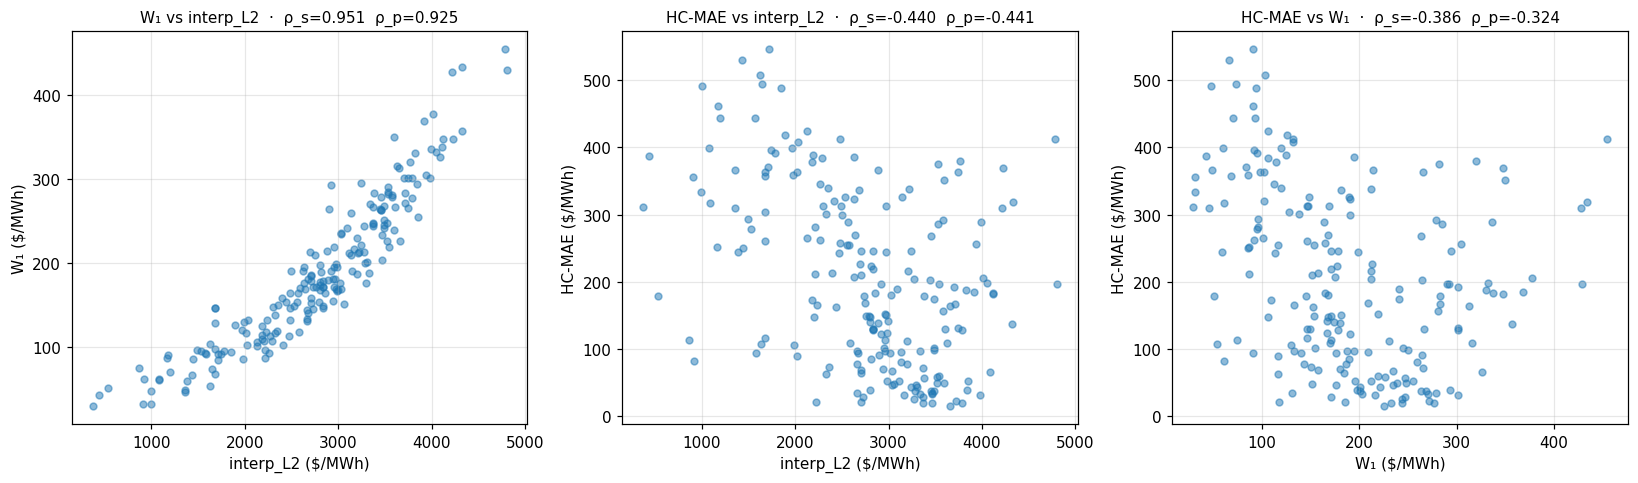

In [7]:
emb_anchor = np.asarray(anchor['embedding'], dtype=float)
emb_others = np.vstack([np.asarray(r['embedding'], dtype=float) for _, r in sample.iloc[1:].iterrows()])
L2 = np.linalg.norm(emb_others - emb_anchor, axis=1)

# 3-way Spearman matrix
names = ['interp_L2', 'W₁', 'HC-MAE']
vecs = [L2, W, dists]
M = np.zeros((3, 3))
for i in range(3):
    for j in range(3):
        M[i, j] = float(spearmanr(vecs[i], vecs[j]).statistic)
print('Spearman ρ matrix (rows = cols = predictor):')
print(pd.DataFrame(M.round(3), index=names, columns=names).to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (x, y, xn, yn) in zip(axes, [
    (L2, W,      'interp_L2', 'W₁'),
    (L2, dists,  'interp_L2', 'HC-MAE'),
    (W,  dists,  'W₁',        'HC-MAE'),
]):
    ax.scatter(x, y, s=20, alpha=0.5, color='C0')
    ax.set_xlabel(f'{xn} ($/MWh)'); ax.set_ylabel(f'{yn} ($/MWh)')
    rho = float(spearmanr(x, y).statistic)
    pr = float(pearsonr(x, y).statistic)
    ax.set_title(f'{yn} vs {xn}  ·  ρ_s={rho:.3f}  ρ_p={pr:.3f}', fontsize=10)
plt.tight_layout(); plt.show()

## Where embedding-L2 disagrees with HC-MAE

These are the pairs that downstream retrieval models would *get wrong* if they keep ranking candidates by interp-L2 but we adopt HC-MAE as the evaluation metric.

- **Top row**: `interp-L2` ranks the pair relatively far but `HC-MAE` ranks them close → retrieval throws away curves that HC-MAE thinks are good matches.
- **Bottom row**: `interp-L2` ranks them close but `HC-MAE` ranks them far → retrieval picks curves that HC-MAE thinks are bad matches.

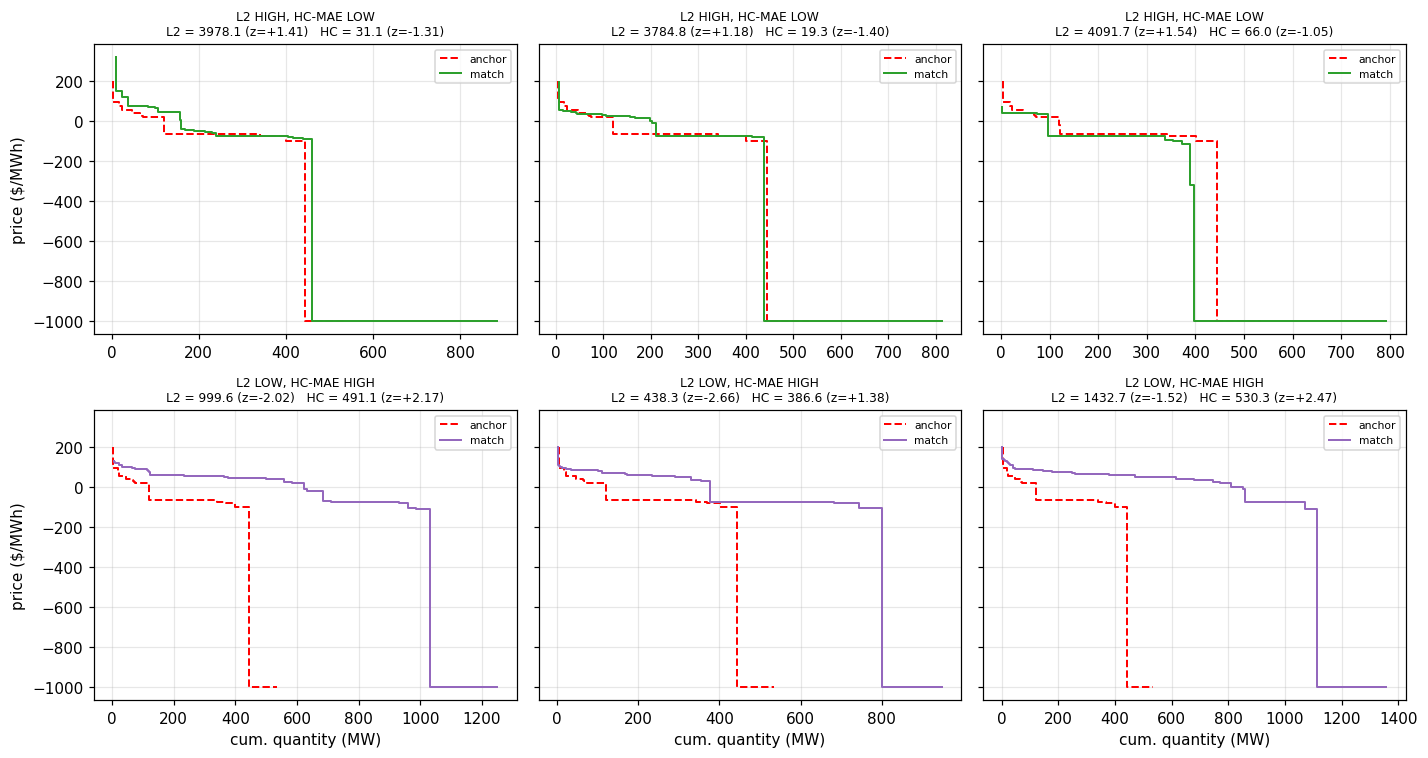

       case  pair_date  interval      L2  HC_MAE  z_L2  z_HC  delta_z
L2 ≫ HC-MAE 2024-01-20        15 3978.12   31.14  1.41 -1.31     2.72
L2 ≫ HC-MAE 2021-09-16        17 3784.83   19.33  1.18 -1.40     2.58
L2 ≫ HC-MAE 2024-02-22        41 4091.67   65.95  1.54 -1.05     2.58
HC-MAE ≫ L2 2022-08-19        24  999.60  491.14 -2.02  2.17    -4.19
HC-MAE ≫ L2 2022-09-21        18  438.28  386.62 -2.66  1.38    -4.05
HC-MAE ≫ L2 2022-07-26        23 1432.65  530.29 -1.52  2.47    -3.99


In [8]:
z_L2 = (L2 - L2.mean()) / L2.std()
dz_L2_HC = z_L2 - z_HC                          # positive → L2 relatively higher than HC-MAE

idx_l2_high = np.argsort(-dz_L2_HC)[:3]         # interp-L2 thinks far, HC-MAE thinks close
idx_hc_high2 = np.argsort(dz_L2_HC)[:3]         # interp-L2 thinks close, HC-MAE thinks far

fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey=True)
for col, idx in enumerate(idx_l2_high):
    ax = axes[0, col]
    other = sample.iloc[idx + 1]
    step_plot(ax, anchor['curve_qty'], anchor['curve_price'], color='red', lw=1.3, ls='--', label='anchor')
    step_plot(ax, other['curve_qty'], other['curve_price'], color='C2', lw=1.3, label='match')
    ax.set_title(f'L2 HIGH, HC-MAE LOW\n'
                 f'L2 = {L2[idx]:.1f} (z={z_L2[idx]:+.2f})   HC = {dists[idx]:.1f} (z={z_HC[idx]:+.2f})',
                 fontsize=8)
    ax.legend(fontsize=7, loc='best')
for col, idx in enumerate(idx_hc_high2):
    ax = axes[1, col]
    other = sample.iloc[idx + 1]
    step_plot(ax, anchor['curve_qty'], anchor['curve_price'], color='red', lw=1.3, ls='--', label='anchor')
    step_plot(ax, other['curve_qty'], other['curve_price'], color='C4', lw=1.3, label='match')
    ax.set_title(f'L2 LOW, HC-MAE HIGH\n'
                 f'L2 = {L2[idx]:.1f} (z={z_L2[idx]:+.2f})   HC = {dists[idx]:.1f} (z={z_HC[idx]:+.2f})',
                 fontsize=8)
    ax.legend(fontsize=7, loc='best')
for ax in axes[-1, :]:
    ax.set_xlabel('cum. quantity (MW)')
axes[0, 0].set_ylabel('price ($/MWh)')
axes[1, 0].set_ylabel('price ($/MWh)')
plt.tight_layout(); plt.show()

# Tabulate
rows = []
for tag, idxs in [('L2 ≫ HC-MAE', idx_l2_high), ('HC-MAE ≫ L2', idx_hc_high2)]:
    for idx in idxs:
        other = sample.iloc[idx + 1]
        rows.append({
            'case': tag,
            'pair_date': str(other['Trading Date']),
            'interval': int(other['Interval Number']),
            'L2': round(float(L2[idx]), 2),
            'HC_MAE': round(float(dists[idx]), 2),
            'z_L2': round(float(z_L2[idx]), 2),
            'z_HC': round(float(z_HC[idx]), 2),
            'delta_z': round(float(dz_L2_HC[idx]), 2),
        })
print(pd.DataFrame(rows).to_string(index=False))

## V-grid embedding — the analytic fix

The previous section showed `interp` embedding L2 is essentially uncorrelated with HC-MAE — because `interp` discretises on a *quantile* grid (it normalises `qty/max_qty`) while HC-MAE integrates on a *volume* grid (it cares about absolute V).

The natural fix is the **V-grid embedding**: sample step price at K equispaced volume positions on `[0, V_max_global]`. By construction `‖z_a − z_b‖₂ ≈ √K · HC-MAE` (per-pair union-support gap aside). Implemented in [`embeddings/v_grid.py`](../src/aemo_curves/embeddings/v_grid.py).

V_max_global (99th pct of train V_total): 1451.7 MW
\nSpearman ρ matrix (rows = cols = predictor), K = 64 :
           interp_L2  v_grid_L2     W₁  HC-MAE
interp_L2      1.000     -0.479  0.951  -0.440
v_grid_L2     -0.479      1.000 -0.426   0.977
W₁             0.951     -0.426  1.000  -0.386
HC-MAE        -0.440      0.977 -0.386   1.000
\nv_grid L2 vs HC-MAE: Spearman = +0.9766   Pearson = +0.9642
Ratio L2 / (sqrt(K)·HC-MAE) — median 1.451, IQR [1.310, 1.829]
(Deviation from 1.0 = the global-grid vs per-pair-union-support discretisation gap)


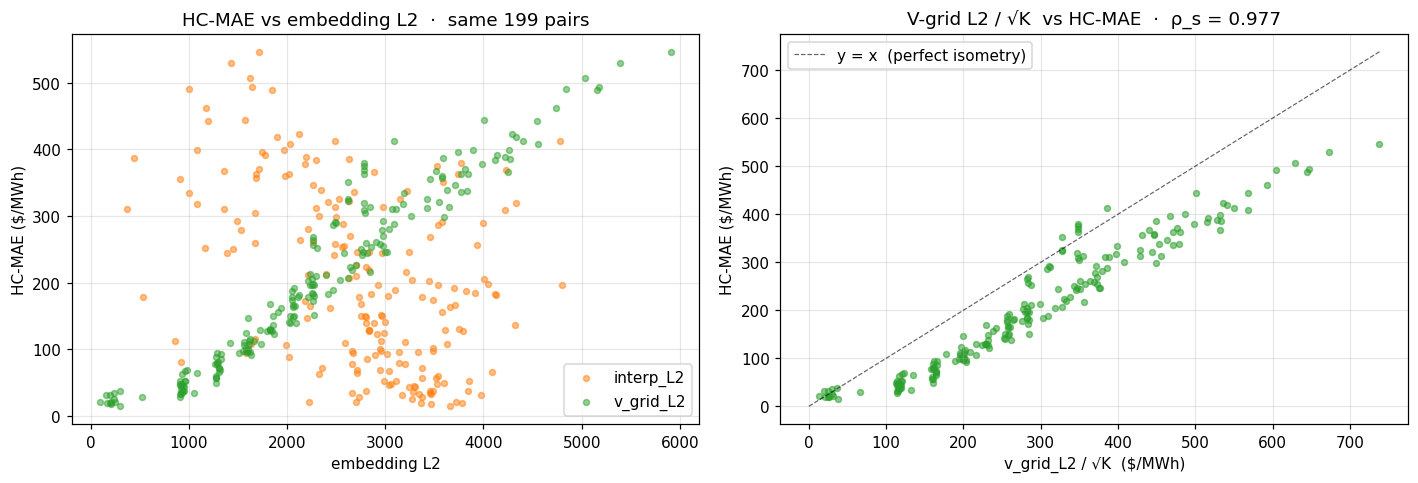

In [9]:
from aemo_curves.embeddings import curve_to_v_grid_embedding, fit_v_max_global

V_MAX = fit_v_max_global(train['curve_qty'])
print(f'V_max_global (99th pct of train V_total): {V_MAX:.1f} MW')

K = 64
v_anchor = curve_to_v_grid_embedding(anchor['curve_qty'], anchor['curve_price'], V_MAX, k=K)
v_others = np.vstack([
    curve_to_v_grid_embedding(r['curve_qty'], r['curve_price'], V_MAX, k=K)
    for _, r in sample.iloc[1:].iterrows()
])
L2_vgrid = np.linalg.norm(v_others - v_anchor, axis=1)

names = ['interp_L2', 'v_grid_L2', 'W₁', 'HC-MAE']
vecs = [L2, L2_vgrid, W, dists]
M = np.zeros((4, 4))
for i in range(4):
    for j in range(4):
        M[i, j] = float(spearmanr(vecs[i], vecs[j]).statistic)
print('\\nSpearman ρ matrix (rows = cols = predictor), K =', K, ':')
print(pd.DataFrame(M.round(3), index=names, columns=names).to_string())

print(f'\\nv_grid L2 vs HC-MAE: Spearman = {spearmanr(L2_vgrid, dists).statistic:+.4f}   '
      f'Pearson = {pearsonr(L2_vgrid, dists).statistic:+.4f}')

# Theoretical check: L2 / sqrt(K) should be in the same units as HC-MAE
ratio = L2_vgrid / np.sqrt(K) / np.clip(dists, 1e-9, None)
print(f'Ratio L2 / (sqrt(K)·HC-MAE) — median {np.median(ratio):.3f}, IQR [{np.quantile(ratio, .25):.3f}, {np.quantile(ratio, .75):.3f}]')
print('(Deviation from 1.0 = the global-grid vs per-pair-union-support discretisation gap)')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(L2, dists, s=15, alpha=0.5, color='C1', label='interp_L2')
axes[0].scatter(L2_vgrid, dists, s=15, alpha=0.5, color='C2', label='v_grid_L2')
axes[0].set_xlabel('embedding L2'); axes[0].set_ylabel('HC-MAE ($/MWh)')
axes[0].set_title('HC-MAE vs embedding L2  ·  same 199 pairs')
axes[0].legend()

axes[1].scatter(L2_vgrid / np.sqrt(K), dists, s=15, alpha=0.55, color='C2')
lo, hi = 0, max(dists.max(), (L2_vgrid / np.sqrt(K)).max())
axes[1].plot([lo, hi], [lo, hi], 'k--', lw=0.8, alpha=0.6, label='y = x  (perfect isometry)')
axes[1].set_xlabel('v_grid_L2 / √K  ($/MWh)'); axes[1].set_ylabel('HC-MAE ($/MWh)')
axes[1].set_title(f'V-grid L2 / √K  vs HC-MAE  ·  ρ_s = {spearmanr(L2_vgrid, dists).statistic:.3f}')
axes[1].legend()
plt.tight_layout(); plt.show()